# 01 · Marketplace health: cleaning, the pay floor, and zones that behave alike

**Question.** Before pricing anything: what does the marketplace look like, where is it
under strain, and which parts of the city behave alike?

**Data.** Every trip by the high-volume app companies in New York City, January 2024 to June 2025
(NYC TLC trip records, about 20 million trips a month). `scripts/build_tables.py` cleaned each month
with PySpark and kept three small outputs: a zone × hour table, an origin–destination table and a
fixed 0.5% trip sample. This notebook works only on those, in SQL (DuckDB).

**Sections**
1. Data quality: what the cleaning removed, by rule
2. The pay floor: how pay is actually set
3. City health by month
4. The weekly rhythm: demand and wait times by hour of week
5. Where riders wait: zones and boroughs
6. Where drivers end up: drop-off vs pickup imbalance
7. Clustering zones into groups that behave alike
8. Verdict

In [1]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

from ridepay import config, data, geo, plots
from ridepay.pay import PAY_CAP_MULTIPLE, floor_pay
from ridepay.records import show_verdict, write_metrics

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
SOURCE = data.source()
con = data.connect()
MONTHS = data.months()
print(f"source: {SOURCE}; months built: {MONTHS[0]} to {MONTHS[-1]} ({len(MONTHS)})")
record = {"months": [MONTHS[0], MONTHS[-1]], "n_months": len(MONTHS)}

source: real; months built: 2024-01 to 2025-06 (18)


## 1. Data quality

Each cleaning rule is counted separately (a trip can fail several). **Trip rules** drop the trip;
**wait rules** keep the trip but treat its wait as missing. Two rules were changed after the first
real month showed they were wrong: drop-offs outside NYC (zone 265) are real trips and are kept,
and a pickup logged before the request makes only the *wait* unusable, not the trip.

In [2]:
q = data.quality_reports()
fail_cols = [c for c in q.columns if c.startswith("fail_")]
quality = pd.DataFrame({
    "rows (M)": q["rows"] / 1e6,
    "kept %": 100 * q["kept"] / q["rows"],
    "valid wait %": 100 * q["kept_with_valid_wait"] / q["kept"],
})
per_million = (q[fail_cols].div(q["rows"], axis=0) * 1e6).round(0)
per_million.columns = [c.removeprefix("fail_") for c in fail_cols]
display_quality = pd.concat([quality.round(2), per_million.astype(int)], axis=1)
print("Rows failing each rule, per million rows:")
display_quality

Rows failing each rule, per million rows:


,rows (M),kept %,valid wait %,request_in_month,valid_zones,dropoff_after_pickup,miles_positive,duration_ok,fare_positive,pay_positive,pickup_after_request,wait_under_2h
month,,,,,,,,,,,,
2024-01,19.66,99.90,99.05,44,39,0,252,99,389,240,9573,1
2024-02,19.36,99.90,98.98,73,38,0,226,93,456,258,10291,1
2024-03,21.28,99.94,99.16,108,37,0,205,76,69,218,8380,1
2024-04,19.73,99.94,99.12,85,39,0,200,83,54,212,8775,1
2024-05,20.70,99.94,99.10,77,41,0,205,80,42,233,8999,1
2024-06,20.12,99.93,99.09,182,43,0,240,79,45,249,9124,1
2024-07,19.18,99.93,99.04,118,42,0,257,86,63,227,9588,1
2024-08,19.13,99.93,99.06,87,41,0,277,82,55,232,9376,2
2024-09,19.21,99.92,99.04,182,39,0,235,76,103,273,9585,2


In [3]:
total_rows, total_kept = int(q["rows"].sum()), int(q["kept"].sum())
record["quality"] = {
    "rows": total_rows, "kept": total_kept, "kept_pct": 100 * total_kept / total_rows,
    "valid_wait_pct": 100 * q["kept_with_valid_wait"].sum() / total_kept,
    "per_million": per_million.mean().round(1).to_dict(),
}
print(f"{total_rows:,} trips; kept {total_kept:,} ({record['quality']['kept_pct']:.2f}%); "
      f"valid wait on {record['quality']['valid_wait_pct']:.2f}% of kept trips")

360,465,639 trips; kept 360,033,346 (99.88%); valid wait on 99.00% of kept trips


## 2. The pay floor

New York sets a minimum pay per mile and per minute for app drivers (raised every 1 March).
If pay were set freely we would see a smooth spread of pay per trip. Instead, the ratio
*driver pay ÷ the minimum for that trip* tells us how pay is actually set.

In [4]:
trips = data.trip_sample(["month", "request_datetime", "PULocationID", "DOLocationID", "trip_miles",
                          "trip_time", "base_passenger_fare", "driver_pay", "tips", "is_airport"])
trips["floor"] = floor_pay(trips["trip_miles"], trips["trip_time"] / 60, trips["request_datetime"],
                           trips["DOLocationID"])
trips["ratio"] = trips["driver_pay"] / trips["floor"]
floor_by_month = trips.groupby("month")["ratio"].agg(
    median="median",
    at_floor_pct=lambda r: 100 * r.between(0.99, 1.01).mean(),
    below_floor_pct=lambda r: 100 * (r < 0.99).mean(),
    above_cap_pct=lambda r: 100 * (r > PAY_CAP_MULTIPLE).mean(),
).round(3)
floor_by_month

,median,at_floor_pct,below_floor_pct,above_cap_pct
month,,,,
2024-01,1.009,50.139,4.094,13.882
2024-02,1.009,50.200,4.220,16.087
2024-03,1.003,55.122,4.432,12.372
2024-04,1.003,58.155,4.661,12.279
2024-05,1.003,57.189,4.734,13.044
2024-06,1.003,54.757,4.723,13.606
2024-07,1.003,59.297,4.936,11.132
2024-08,1.003,59.180,5.024,12.058
2024-09,1.004,50.174,5.221,14.116


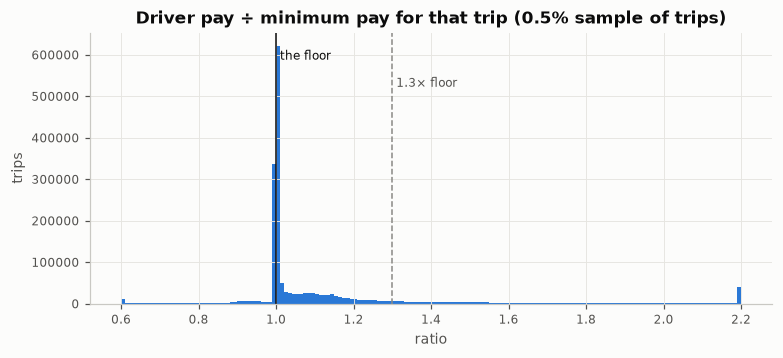

In [5]:
fig, ax = plots.subplots(figsize=(8, 3.2))
ax.hist(trips["ratio"].clip(0.6, 2.2), bins=160, color=plots.SERIES[0])
ax.axvline(1.0, color=plots.INK, lw=1)
ax.axvline(PAY_CAP_MULTIPLE, color=plots.GREY, lw=1, ls="--")
ax.text(1.01, ax.get_ylim()[1] * 0.9, "the floor", fontsize=8, color=plots.INK)
ax.text(PAY_CAP_MULTIPLE + 0.01, ax.get_ylim()[1] * 0.8, f"{PAY_CAP_MULTIPLE}× floor", fontsize=8, color=plots.INK_2)
ax.set(title="Driver pay ÷ minimum pay for that trip (0.5% sample of trips)", xlabel="ratio", ylabel="trips")
data.savefig(fig, "01_pay_to_floor")

In [6]:
at_floor = trips["ratio"].between(0.99, 1.01)
trips["premium"] = (trips["driver_pay"] - trips["floor"]).clip(lower=0)
record["floor"] = {
    "median_ratio": float(trips["ratio"].median()),
    "at_floor_pct": 100 * float(at_floor.mean()),
    "below_floor_pct": 100 * float((trips["ratio"] < 0.99).mean()),
    "above_cap_pct": 100 * float((trips["ratio"] > PAY_CAP_MULTIPLE).mean()),
    "premium_share_of_pay_pct": 100 * float(trips["premium"].sum() / trips["driver_pay"].sum()),
}
print({k: round(v, 2) for k, v in record["floor"].items()})

{'median_ratio': 1.0, 'at_floor_pct': 53.16, 'below_floor_pct': 4.9, 'above_cap_pct': 13.41, 'premium_share_of_pay_pct': 7.88}


**Reading.** The median trip is paid within about 1% of the minimum, and that holds across the
March rate changes: the formula is the platform's base pay in practice. Pay **above** the floor
(the "premium") is what the platform chooses, so it is the lever this project prices. Where does
the premium go? (A few percent of trips are paid slightly *below* the per-trip formula: the real
standard is enforced on weekly earnings, and shared and wheelchair trips have their own rules.)

In [7]:
trips["hour"] = trips["request_datetime"].dt.hour
trips["band"] = trips["hour"].map(config.BAND_OF_HOUR)
trips["miles_bin"] = pd.cut(trips["trip_miles"], [0, 2, 5, 10, 20, 100], labels=["<2", "2-5", "5-10", "10-20", "20+"])
premium_by = (trips.groupby(["miles_bin", "band"], observed=True)
              .apply(lambda g: 100 * g["premium"].sum() / g["floor"].sum(), include_groups=False)
              .unstack()[list(config.HOUR_BANDS)].round(1))
print("Premium as % of floor pay, by trip length and hour band:")
premium_by

Premium as % of floor pay, by trip length and hour band:


band,night,am_peak,midday,pm_peak,evening
miles_bin,,,,,
<2,30.1,20.9,15.5,20.1,25.0
2-5,10.9,8.1,6.4,8.4,10.1
5-10,7.0,5.3,5.1,5.9,6.6
10-20,6.4,6.3,6.2,6.0,5.6
20+,5.1,5.2,5.1,5.4,5.6


## 3. City health by month

All metrics are computed from **sums** in the zone × hour table (total pay ÷ total miles, total
wait ÷ number of valid waits), never by averaging averages.

In [8]:
health_month = con.sql("""
    SELECT month,
           SUM(trips) / 1e6                                   AS trips_m,
           SUM(trips) / COUNT(DISTINCT CAST(hour AS DATE))    AS trips_per_day,
           SUM(wait_sum_sec) / SUM(wait_n) / 60               AS wait_min,
           SUM(driver_pay) / SUM(miles)                       AS pay_per_mile,
           SUM(driver_pay) / (SUM(trip_sec) / 60)             AS pay_per_min,
           SUM(driver_pay) / SUM(fare)                        AS driver_share,
           SUM(tips) / SUM(trips)                             AS tips_per_trip,
           SUM(trips_cbd_fee) / SUM(trips)                    AS cbd_fee_share
    FROM zone_hour GROUP BY month ORDER BY month
""").df().set_index("month")
health_month.round(3)

,trips_m,trips_per_day,wait_min,pay_per_mile,pay_per_min,driver_share,tips_per_trip,cbd_fee_share
month,,,,,,,,
2024-01,19.645,633709.226,4.289,3.779,0.987,0.762,1.058,0.000
2024-02,19.339,666858.138,4.378,3.871,0.993,0.786,1.069,0.000
2024-03,21.267,686031.548,4.622,3.953,0.995,0.766,1.138,0.000
2024-04,19.721,657369.600,4.607,3.934,0.999,0.765,1.176,0.000
2024-05,20.692,667490.548,4.614,4.048,0.989,0.766,1.254,0.000
2024-06,20.108,670274.900,4.862,4.009,1.002,0.767,1.217,0.000
2024-07,19.169,618370.484,4.497,3.842,1.004,0.771,1.131,0.000
2024-08,19.115,616625.065,4.555,3.866,1.008,0.766,1.111,0.000
2024-09,19.194,639797.200,4.896,4.076,0.995,0.774,1.198,0.000


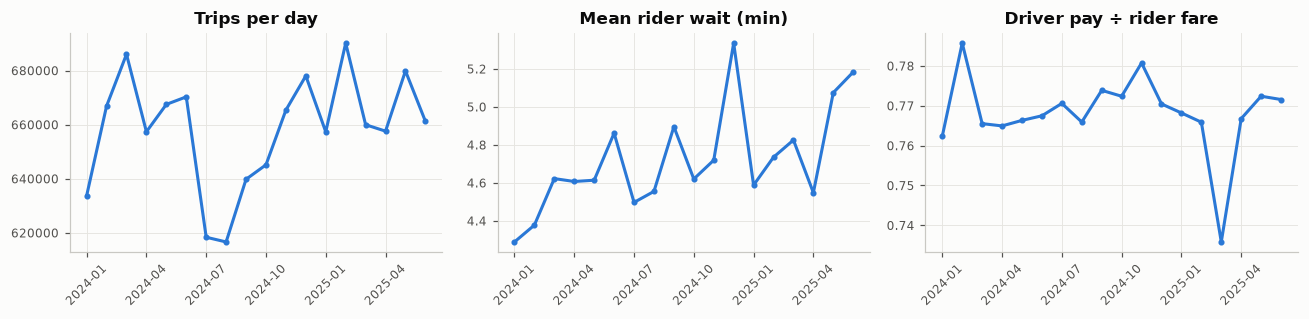

In [9]:
fig, axes = plots.subplots(1, 3, figsize=(12, 3))
for ax, col, title in zip(axes, ["trips_per_day", "wait_min", "driver_share"],
                          ["Trips per day", "Mean rider wait (min)", "Driver pay ÷ rider fare"]):
    ax.plot(range(len(health_month)), health_month[col], marker="o", ms=3, color=plots.SERIES[0])
    ax.set_xticks(range(0, len(health_month), 3), health_month.index[::3], rotation=45)
    ax.set_title(title)
fig.tight_layout()
data.savefig(fig, "01_health_by_month")
record["health_month"] = health_month.round(4).reset_index().to_dict(orient="records")

## 4. The weekly rhythm

Demand (trips) and rider wait by hour of the week. Wait time is where a supply shortage shows
first: when demand rises faster than drivers come online, waits stretch.

correlation of hourly trips and wait: -0.15; longest mean wait 6.1 min (day 6, 4:00)


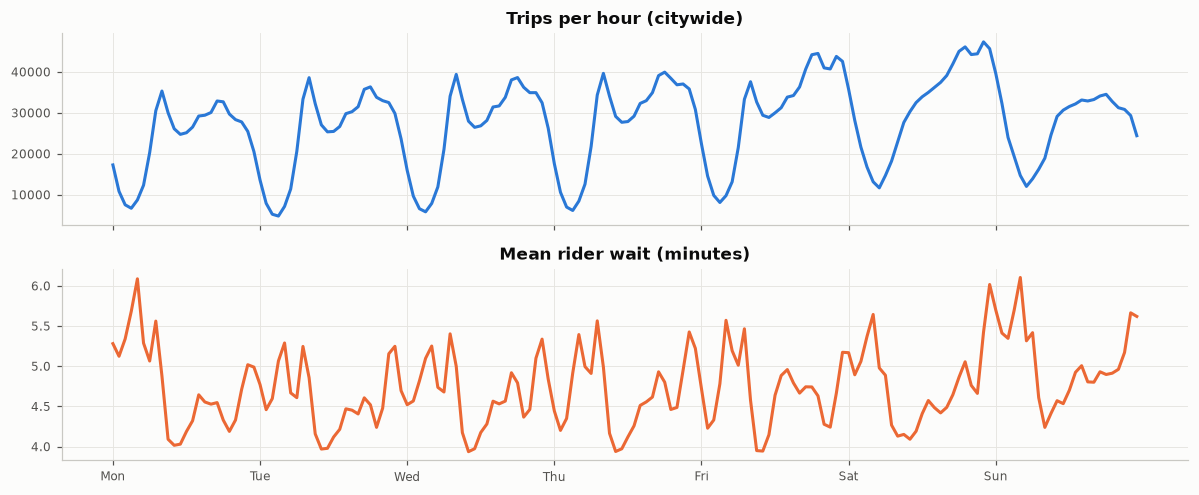

In [10]:
how = con.sql("""
    SELECT isodow(hour) - 1 AS dow, hour(hour) AS hod,
           SUM(trips) / COUNT(DISTINCT CAST(hour AS DATE)) AS trips_per_hour,
           SUM(wait_sum_sec) / SUM(wait_n) / 60           AS wait_min,
           SUM(driver_pay) / SUM(fare)                    AS driver_share
    FROM zone_hour GROUP BY 1, 2 ORDER BY 1, 2
""").df()
how["how"] = how["dow"] * 24 + how["hod"]
fig, axes = plots.subplots(2, 1, figsize=(11, 4.6), sharex=True)
axes[0].plot(how["how"], how["trips_per_hour"], color=plots.SERIES[0])
axes[0].set_title("Trips per hour (citywide)")
axes[1].plot(how["how"], how["wait_min"], color=plots.SERIES[1])
axes[1].set_title("Mean rider wait (minutes)")
axes[1].set_xticks(range(0, 168, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
fig.tight_layout()
data.savefig(fig, "01_hour_of_week")
corr = float(np.corrcoef(how["trips_per_hour"], how["wait_min"])[0, 1])
peak_wait = how.loc[how["wait_min"].idxmax()]
record["weekly"] = {"corr_trips_wait": corr, "peak_wait_min": float(peak_wait["wait_min"]),
                    "peak_wait_dow": int(peak_wait["dow"]), "peak_wait_hod": int(peak_wait["hod"]),
                    "min_wait_min": float(how["wait_min"].min())}
print(f"correlation of hourly trips and wait: {corr:.2f}; longest mean wait {peak_wait['wait_min']:.1f} min "
      f"(day {int(peak_wait['dow'])}, {int(peak_wait['hod'])}:00)")

## 5. Where riders wait

In [11]:
zone_stats = con.sql("""
    WITH z AS (
        SELECT zone,
               SUM(trips) / COUNT(DISTINCT CAST(hour AS DATE))         AS trips_per_day,
               SUM(wait_sum_sec) / SUM(wait_n) / 60                   AS wait_min,
               SUM(wait_p90_sec * wait_n) / SUM(wait_n) / 60          AS wait_p90_min,
               SUM(driver_pay) / SUM(miles)                           AS pay_per_mile,
               SUM(miles) / SUM(trips)                                AS miles_per_trip,
               SUM(driver_pay) / SUM(fare)                            AS driver_share,
               SUM(trips_airport) / SUM(trips)                        AS airport_share,
               SUM(trips_cbd_fee) / SUM(trips)                        AS cbd_fee_share,
               SUM(trips)                                             AS trips
        FROM zone_hour GROUP BY zone)
    SELECT z.*, zones.zone_name, zones.borough
    FROM z JOIN zones USING (zone) ORDER BY zone
""").df().set_index("zone")
days = con.sql("SELECT COUNT(DISTINCT CAST(hour AS DATE)) FROM zone_hour").fetchall()[0][0]

borough = con.sql("""
    SELECT zones.borough,
           SUM(trips) / 1e6                                           AS trips_m,
           SUM(wait_sum_sec) / SUM(wait_n) / 60                       AS wait_min,
           SUM(CASE WHEN hour(hour) BETWEEN 16 AND 19 THEN wait_sum_sec END)
             / SUM(CASE WHEN hour(hour) BETWEEN 16 AND 19 THEN wait_n END) / 60 AS pm_peak_wait_min,
           SUM(driver_pay) / SUM(miles)                               AS pay_per_mile,
           SUM(driver_pay) / SUM(fare)                                AS driver_share
    FROM zone_hour JOIN zones USING (zone)
    GROUP BY 1 ORDER BY trips_m DESC
""").df().set_index("borough")
borough.round(3)

,trips_m,wait_min,pm_peak_wait_min,pay_per_mile,driver_share
borough,,,,,
Manhattan,138.162,4.478,4.641,4.263,0.716
Brooklyn,95.497,4.725,4.496,4.259,0.803
Queens,75.901,4.996,4.783,3.544,0.798
Bronx,45.082,4.884,4.803,3.810,0.848
Staten Island,5.392,5.786,5.361,3.405,0.821
EWR,0.000,37.791,NaN,22.553,0.738


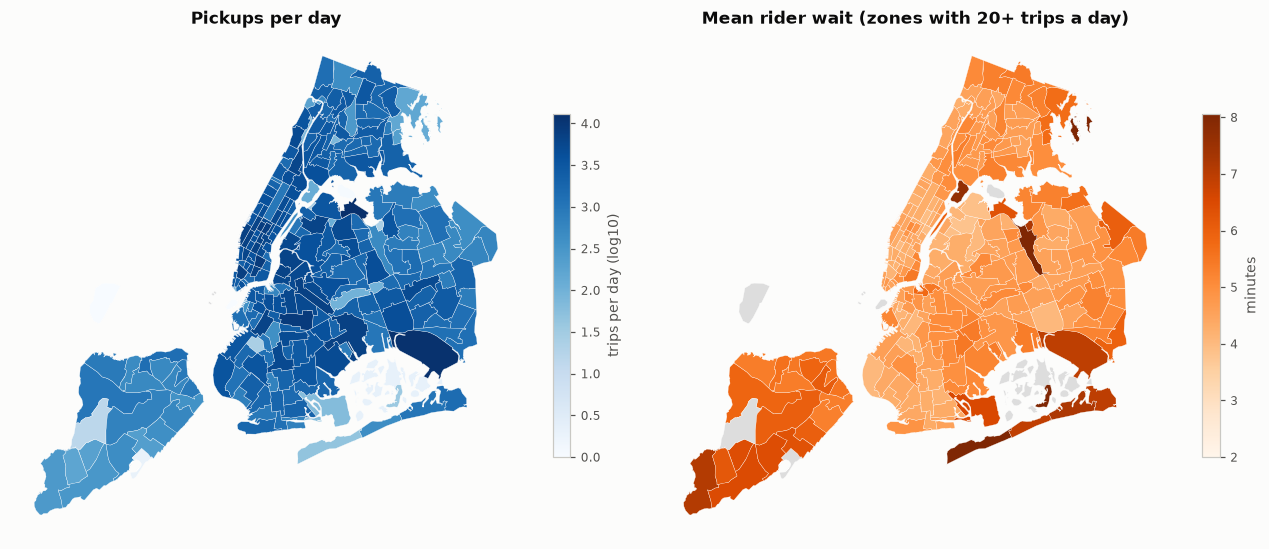

In [12]:
fig, axes = plots.subplots(1, 2, figsize=(12, 5.5))
sm = geo.plot_zones(axes[0], np.log10(zone_stats["trips_per_day"].clip(lower=1)), cmap=plots.SEQUENTIAL)
fig.colorbar(sm, ax=axes[0], shrink=0.6, label="trips per day (log10)")
axes[0].set_title("Pickups per day")
sm = geo.plot_zones(axes[1], zone_stats["wait_min"].where(zone_stats["trips_per_day"] >= 20),
                    cmap="Oranges", vmin=2, vmax=zone_stats["wait_min"].quantile(0.97))
fig.colorbar(sm, ax=axes[1], shrink=0.6, label="minutes")
axes[1].set_title("Mean rider wait (zones with 20+ trips a day)")
fig.tight_layout()
data.savefig(fig, "01_zone_maps")
record["borough"] = borough.round(4).reset_index().to_dict(orient="records")

## 6. Where drivers end up

A driver who drops a rider in a zone with few new requests drives back empty (dead-heads).
For each zone: drop-offs ÷ pickups. Above 1, drivers accumulate there with too little work;
trips *into* those zones are harder to place, so they are where an incentive is most likely.

In [13]:
imbalance = con.sql("""
    WITH arrivals AS (SELECT do_zone AS zone, SUM(trips) AS dropoffs FROM od_hour GROUP BY 1),
         departures AS (SELECT pu_zone AS zone, SUM(trips) AS pickups FROM od_hour GROUP BY 1)
    SELECT zone, dropoffs, pickups, dropoffs / pickups AS arrivals_per_pickup
    FROM arrivals JOIN departures USING (zone) ORDER BY zone
""").df().set_index("zone")
zone_stats = zone_stats.join(imbalance["arrivals_per_pickup"])
print("Zones where drivers pile up (20+ pickups a day, most drop-offs per pickup):")
(zone_stats[zone_stats["trips_per_day"] >= 20]
 .sort_values("arrivals_per_pickup", ascending=False)
 [["zone_name", "borough", "trips_per_day", "arrivals_per_pickup", "wait_min"]].head(8).round(2))

Zones where drivers pile up (20+ pickups a day, most drop-offs per pickup):


,zone_name,borough,trips_per_day,arrivals_per_pickup,wait_min
zone,,,,,
194,Randalls Island,Manhattan,124.33,2.12,7.67
12,Battery Park,Manhattan,70.53,1.70,4.54
93,Flushing Meadows-Corona Park,Queens,485.23,1.50,8.26
27,Breezy Point/Fort Tilden/Riis Beach,Queens,45.52,1.46,10.06
120,Highbridge Park,Manhattan,65.68,1.43,4.79
154,Marine Park/Floyd Bennett Field,Brooklyn,64.84,1.43,6.53
43,Central Park,Manhattan,970.93,1.40,4.29
190,Prospect Park,Brooklyn,394.27,1.39,4.80


## 7. Clustering zones

Pay policy needs segments, and 263 zones are too many to price one by one (many have a handful
of trips an hour, so per-zone estimates would be noise). Zones are grouped on **how they behave**,
not on where they are:

* volume (log trips per day) and the daily shape (share of trips in each hour band, weekend share);
* service level (mean wait, and the 90th-percentile wait relative to the mean);
* trip economics (miles per trip, pay per mile, airport share);
* driver flow (drop-offs per pickup).

Features are standardized so none dominates by its units. Two groups are set by rule, not by the
fit: the three **airports** (they dispatch from queues, a different marketplace) and zones with fewer
than 5 trips a day (parks, cemeteries, industrial areas), labelled "sparse".

**Choosing k.** Silhouette (how well-separated the groups are) and **stability**: refit on
bootstrap resamples of zones and check that zones stay grouped together (adjusted Rand index).
A segmentation that changes when a few zones are resampled can't carry a pay policy.

In [14]:
shape = con.sql("""
    SELECT zone,
           SUM(CASE WHEN hour(hour) < 6 THEN trips END) / SUM(trips)                AS share_night,
           SUM(CASE WHEN hour(hour) BETWEEN 6 AND 9 THEN trips END) / SUM(trips)    AS share_am_peak,
           SUM(CASE WHEN hour(hour) BETWEEN 16 AND 19 THEN trips END) / SUM(trips)  AS share_pm_peak,
           SUM(CASE WHEN hour(hour) >= 20 THEN trips END) / SUM(trips)              AS share_evening,
           SUM(CASE WHEN isodow(hour) >= 6 THEN trips END) / SUM(trips)             AS share_weekend
    FROM zone_hour GROUP BY zone ORDER BY zone
""").df().set_index("zone").fillna(0)
feats = zone_stats.join(shape)
feats["log_trips"] = np.log10(feats["trips_per_day"])
feats["wait_tail"] = feats["wait_p90_min"] / feats["wait_min"]
FEATURES = ["log_trips", "share_night", "share_am_peak", "share_pm_peak", "share_evening", "share_weekend",
            "wait_min", "wait_tail", "miles_per_trip", "pay_per_mile", "airport_share", "arrivals_per_pickup"]
is_airport_zone = feats.index.isin(config.AIRPORT_ZONES)
active = feats[(feats["trips_per_day"] >= 5) & ~is_airport_zone].dropna(subset=FEATURES)
X = StandardScaler().fit_transform(active[FEATURES])
print(f"{len(active)} zones clustered; {int(is_airport_zone.sum())} airports; "
      f"{len(feats) - len(active) - int(is_airport_zone.sum())} sparse")

rng = np.random.default_rng(7)
rows = []
for k in range(3, 9):
    base = KMeans(k, n_init=20, random_state=0).fit(X)
    aris = []
    for _ in range(20):
        idx = rng.choice(len(X), len(X), replace=True)
        boot = KMeans(k, n_init=5, random_state=int(rng.integers(1e6))).fit(X[idx])
        aris.append(adjusted_rand_score(base.labels_, boot.predict(X)))
    rows.append({"k": k, "silhouette": silhouette_score(X, base.labels_), "stability_ari": np.mean(aris),
                 "smallest_cluster": np.bincount(base.labels_).min()})
choose_k = pd.DataFrame(rows).set_index("k").round(3)
choose_k

254 zones clustered; 3 airports; 4 sparse


,silhouette,stability_ari,smallest_cluster
k,,,
3,0.262,0.838,19
4,0.187,0.660,16
5,0.201,0.742,16
6,0.211,0.740,7
7,0.172,0.577,4
8,0.202,0.570,3


Rule, fixed before looking: the k with the highest silhouette among those with stability ARI ≥ 0.8
and no cluster smaller than 5 zones; ties go to the smaller k (simpler policy).

In [15]:
ok = choose_k[(choose_k["stability_ari"] >= 0.8) & (choose_k["smallest_cluster"] >= 5)]
K = int((ok if len(ok) else choose_k)["silhouette"].idxmax())
km = KMeans(K, n_init=50, random_state=0).fit(X)
active = active.assign(cluster=km.labels_)
profile = active.groupby("cluster").agg(
    zones=("zone_name", "size"), trips_per_day=("trips_per_day", "sum"),
    **{f: (f, "median") for f in FEATURES if f != "log_trips"})
profile["trip_share_pct"] = 100 * profile["trips_per_day"] / feats["trips_per_day"].sum()
print(f"k = {K}")
profile.round(2).T

k = 3


cluster,0,1,2
zones,78.00,19.00,157.00
trips_per_day,328690.09,3422.07,301278.15
share_night,0.12,0.09,0.11
share_am_peak,0.14,0.11,0.22
share_pm_peak,0.23,0.28,0.21
share_evening,0.23,0.19,0.17
share_weekend,0.33,0.37,0.29
wait_min,4.49,6.53,4.76
wait_tail,1.65,1.67,1.63
miles_per_trip,4.81,5.77,4.62


**Naming clusters from their profile** (a rule, so names follow the data if it is rebuilt): the
cluster with the highest median volume is the *Core*; the one with the longest median wait is
*Long waits*; any other cluster is named after the feature where it stands out most (largest
standardized median among a short list of readable traits).

In [16]:
TRAITS = {"share_am_peak": "Commuter residential", "share_night": "Nightlife", "share_weekend": "Weekend leisure",
          "miles_per_trip": "Long trips", "arrivals_per_pickup": "Drop-off heavy", "share_evening": "Evening",
          "pay_per_mile": "High pay per mile"}


def name_clusters(active: pd.DataFrame) -> dict[int, str]:
    med = active.groupby("cluster")[FEATURES].median()
    z = (med - active[FEATURES].mean()) / active[FEATURES].std()
    names, left = {}, list(med.index)
    core = med.loc[left, "log_trips"].idxmax()
    names[core] = "Core"
    left.remove(core)
    if left:
        slow = med.loc[left, "wait_min"].idxmax()
        names[slow] = "Long waits"
        left.remove(slow)
    for c in sorted(left, key=lambda c: -z.loc[c, list(TRAITS)].max()):
        for trait in z.loc[c, list(TRAITS)].sort_values(ascending=False).index:
            if TRAITS[trait] not in names.values():
                names[c] = TRAITS[trait]
                break
    return names


names = name_clusters(active)
profile.insert(0, "name", profile.index.map(names))
clusters = feats[["zone_name", "borough", "trips_per_day"]].join(active["cluster"])
clusters["cluster_name"] = clusters["cluster"].map(names).fillna("Sparse")
clusters["cluster"] = clusters["cluster"].fillna(-1).astype(int)
all_zones = geo.centroids().set_index("zone")
clusters = all_zones[["zone_name", "borough"]].join(clusters[["trips_per_day", "cluster", "cluster_name"]])
clusters["cluster"] = clusters["cluster"].fillna(-1).astype(int)
clusters["cluster_name"] = clusters["cluster_name"].fillna("Sparse")
airport = clusters.index.isin(config.AIRPORT_ZONES)
clusters.loc[airport, "cluster"], clusters.loc[airport, "cluster_name"] = K, "Airports"
print(clusters.groupby(["cluster_name", "borough"]).size().unstack(fill_value=0))
profile[["name", "zones", "trip_share_pct", "wait_min", "miles_per_trip", "pay_per_mile",
         "airport_share", "share_night", "arrivals_per_pickup"]].round(2)

borough               Bronx  Brooklyn  EWR  Manhattan  Queens  Staten Island
cluster_name                                                                
Airports                  0         0    1          0       2              0
Commuter residential     39        31    0         19      52             16
Core                      0        27    0         44       7              0
Long waits                3         3    0          3       7              3
Sparse                    1         0    0          3       1              1


,name,zones,trip_share_pct,wait_min,miles_per_trip,pay_per_mile,airport_share,share_night,arrivals_per_pickup
cluster,,,,,,,,,
0,Core,78,49.94,4.49,4.81,4.28,0.06,0.12,0.94
1,Long waits,19,0.52,6.53,5.77,3.58,0.03,0.09,1.16
2,Commuter residential,157,45.77,4.76,4.62,3.76,0.03,0.11,0.96


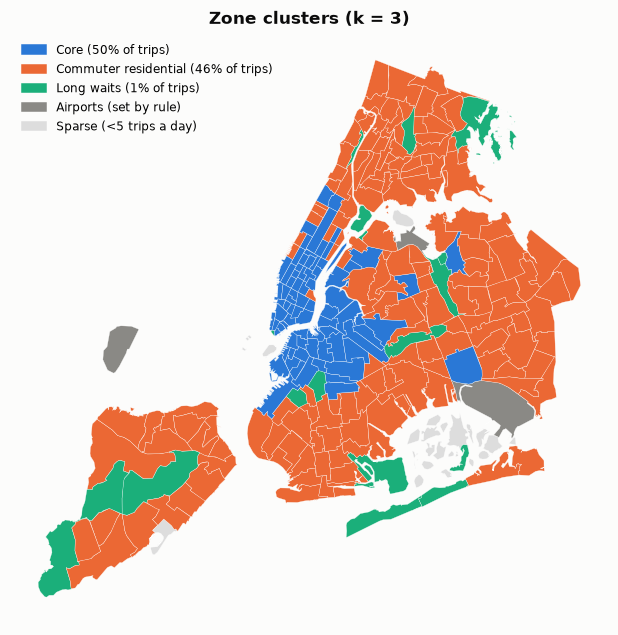

In [17]:
fig, ax = plots.subplots(figsize=(7, 7))
order = profile.sort_values("trip_share_pct", ascending=False).index.tolist()
color_of = {c: plots.SERIES[i] for i, c in enumerate(order)}
from matplotlib.collections import PolyCollection  # noqa: E402
from matplotlib.patches import Patch  # noqa: E402

shapes = geo.outlines()
polys, cols = [], []
for zid, rings in shapes.items():
    c = clusters["cluster"].get(zid, -1)
    for ring in rings:
        polys.append(ring)
        cols.append(color_of.get(c, plots.GREY if c == K else "#dddddd"))
ax.add_collection(PolyCollection(polys, facecolors=cols, edgecolors="white", linewidths=0.2))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(handles=[Patch(color=color_of[c], label=f"{names[c]} ({profile.loc[c, 'trip_share_pct']:.0f}% of trips)")
                   for c in order] + [Patch(color=plots.GREY, label="Airports (set by rule)"),
                                      Patch(color="#dddddd", label="Sparse (<5 trips a day)")],
          loc="upper left", fontsize=8)
ax.set_title(f"Zone clusters (k = {K})")
data.savefig(fig, "01_zone_clusters")

In [18]:
_ = data.save_table(clusters.reset_index(), "zone_clusters")
record["clusters"] = {
    "k": K, "choose_k": choose_k.reset_index().to_dict(orient="records"),
    "profile": profile.reset_index().round(4).to_dict(orient="records"),
    "n_sparse_zones": int((clusters["cluster"] == -1).sum()),
}
record["days"] = int(days)
_ = write_metrics("01_marketplace_health", record, SOURCE)

## 8. Verdict

In [19]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
h = health_month
core = profile.loc[profile["name"] == "Core"]
longest = profile.sort_values("wait_min").iloc[-1]
fq, fl = record["quality"], record["floor"]
show_verdict(
    "Verdict: phase 1, marketplace health",
    [
        f"**The data is clean and trustworthy after counted rules.** {fq['rows']/1e6:,.0f}M trips over "
        f"{record['n_months']} months; {fq['kept_pct']:.2f}% kept. The largest issue, pickups logged before the "
        f"request, makes only the wait unusable ({100 - fq['valid_wait_pct']:.1f}% of trips), so those trips stay in "
        "every pay and volume metric.",
        f"**Pay is set by the regulatory floor, plus a premium.** The median trip is paid "
        f"{fl['median_ratio']:.3f}× the minimum for its miles and minutes; {fl['at_floor_pct']:.0f}% are within 1% of it. "
        f"The premium above the floor is {fl['premium_share_of_pay_pct']:.1f}% of all driver pay and "
        f"{fl['above_cap_pct']:.1f}% of trips are paid above {PAY_CAP_MULTIPLE}× the floor. The premium is the lever this "
        "project prices.",
        f"**Waits measure the supply–demand balance, not demand.** Mean rider wait runs from "
        f"{record['weekly']['min_wait_min']:.1f} to {record['weekly']['peak_wait_min']:.1f} minutes across the week; the "
        f"longest is {DAYS[record['weekly']['peak_wait_dow']]} {record['weekly']['peak_wait_hod']}:00, and its correlation "
        f"with hourly trips is {record['weekly']['corr_trips_wait']:.2f}. "
        + ("Waits are longest when drivers are scarce (late night), not at demand peaks, so a pay lever should "
           "target hours by their balance, not their volume. " if record['weekly']['corr_trips_wait'] < 0 else "")
        + f"Drivers' share of the fare is {h['driver_share'].min():.1%}–{h['driver_share'].max():.1%} by month.",
        f"**{K} zone clusters, stable under resampling** (silhouette {choose_k.loc[K, 'silhouette']:.2f}, bootstrap ARI "
        f"{choose_k.loc[K, 'stability_ari']:.2f}). "
        + (f"The Core carries {core['trip_share_pct'].iloc[0]:.0f}% of trips; " if len(core) else "")
        + f"'{longest['name']}' ({int(longest['zones'])} zones) has the longest median wait ({longest['wait_min']:.1f} min). These clusters are the "
        "segments for forecasting, the pay-to-accept model and the pay policy.",
    ],
    "phase 2: forecast trips by zone and hour four weeks ahead, the input to supply and incentive planning.",
)

### Verdict: phase 1, marketplace health

1. **The data is clean and trustworthy after counted rules.** 360M trips over 18 months; 99.88% kept. The largest issue, pickups logged before the request, makes only the wait unusable (1.0% of trips), so those trips stay in every pay and volume metric.
2. **Pay is set by the regulatory floor, plus a premium.** The median trip is paid 1.003× the minimum for its miles and minutes; 53% are within 1% of it. The premium above the floor is 7.9% of all driver pay and 13.4% of trips are paid above 1.3× the floor. The premium is the lever this project prices.
3. **Waits measure the supply–demand balance, not demand.** Mean rider wait runs from 3.9 to 6.1 minutes across the week; the longest is Sunday 4:00, and its correlation with hourly trips is -0.15. Waits are longest when drivers are scarce (late night), not at demand peaks, so a pay lever should target hours by their balance, not their volume. Drivers' share of the fare is 73.6%–78.6% by month.
4. **3 zone clusters, stable under resampling** (silhouette 0.26, bootstrap ARI 0.84). The Core carries 50% of trips; 'Long waits' (19 zones) has the longest median wait (6.5 min). These clusters are the segments for forecasting, the pay-to-accept model and the pay policy.

**Next:** phase 2: forecast trips by zone and hour four weeks ahead, the input to supply and incentive planning.